# 02 — Preprocessing and Merging

Convert raw phyphox exports into a clean, uniform, per-session merged dataset.

**Inputs:** `data/raw/<participant>/<mode>_<day>/*.csv` — phyphox exports.

**Outputs:**
- `data/interim/<session_id>.csv` — one wide-format file per session at 50 Hz with all sensors aligned.
- `data/interim/sessions_index.csv` — index of all processed sessions with metadata.
- `data/interim/preprocessing_log.csv` — diagnostics per session (gaps, drop counts, etc.).

**What this notebook does:**
1. Discovers sensor files via fuzzy filename matching (handles different phyphox naming across iOS / Android / locales).
2. Drops duplicate timestamps.
3. Resamples every sensor to a common 50 Hz time grid using linear interpolation.
4. Trims the first and last 10 seconds of each recording to remove start/stop artefacts.
5. Merges sensors into a single wide-format CSV per session.
6. Records any gaps and downsampling decisions in the log.

**Data quality decisions encoded here (defendable in the report):**
- *Sampling rate heterogeneity*: participant 1 recorded at ~100 Hz, participants 2 and 3 at ~50 Hz. We downsample everyone to 50 Hz via linear interpolation onto a common grid.
- *Linear accelerometer naming*: phyphox names this file differently across platforms (`Linear Accelerometer.csv` vs `Linear Acceleration.csv`). We match both.
- *Duplicate timestamps* (<1% of samples in some sessions): dropped, keeping the first occurrence.
- *Barometer*: when available, included at 50 Hz via forward-fill (native rate is ~1 Hz). When absent, the column is NaN. Not used in the main model — see plan section 8.

## Imports

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings('ignore')
pd.set_option('display.max_rows', 200)
pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 200)

## Configuration

Edit `DATA_ROOT` only if the layout differs from the plan.

In [9]:
DATA_ROOT = Path('../data/raw')
INTERIM_DIR = Path('../data/interim')
REPORTS_DIR = Path('../reports')
INTERIM_DIR.mkdir(parents=True, exist_ok=True)
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

PARTICIPANTS = ['babis', 'athina', 'xiomara']
MODES = ['stationary', 'walking', 'cycling', 'metro', 'bus', 'tram']
DAYS = ['day1', 'day2', 'day3']

TARGET_RATE_HZ = 50
TRIM_SECONDS = 10            # remove the first/last 10 s of each recording
MAX_GAP_INTERP_S = 0.5      # gaps larger than this are flagged; interpolation still runs but values are unreliable

print(f'DATA_ROOT   : {DATA_ROOT.resolve()}')
print(f'INTERIM_DIR : {INTERIM_DIR.resolve()}')
print(f'Target rate : {TARGET_RATE_HZ} Hz')
print(f'Edge trim   : {TRIM_SECONDS} s on each side')

DATA_ROOT   : C:\Projects\this project-transport-mode\data\raw
INTERIM_DIR : C:\Projects\this project-transport-mode\data\interim
Target rate : 50 Hz
Edge trim   : 10 s on each side


## Sensor file discovery (fuzzy matching)

Phyphox names exports differently across platforms. Babis's iPhone exported `Linear Accelerometer.csv`;
Athina and Xiomara's phones exported `Linear Acceleration.csv` for the same physical sensor.
Rather than rename files manually, we match filenames against a small alias table.

In [10]:
SENSOR_ALIASES = {
    'accelerometer': [
        'accelerometer.csv',
        'acceleration.csv',
        'raw_accelerometer.csv',
    ],
    'linear_accelerometer': [
        'linear accelerometer.csv',
        'linear acceleration.csv',
        'linearaccelerometer.csv',
        'linearacceleration.csv',
        'acceleration without g.csv',
        'linear_accelerometer.csv',
        'linear_acceleration.csv',
    ],
    'gyroscope': [
        'gyroscope.csv',
        'gyro.csv',
        'gyroscope rotation rate.csv',
    ],
    'barometer': [
        'barometer.csv',
        'pressure.csv',
        'atmospheric pressure.csv',
    ],
}

REQUIRED_SENSORS = {'accelerometer', 'linear_accelerometer', 'gyroscope'}


def classify_filename(filename):
    norm = filename.lower().strip()
    for sensor, aliases in SENSOR_ALIASES.items():
        if norm in aliases:
            return sensor
    return None


def discover_session_sensors(folder):
    """Return dict sensor_type -> Path for files found in a session folder."""
    found = {}
    if not folder.exists():
        return found
    for f in folder.iterdir():
        if f.is_file() and f.suffix.lower() == '.csv':
            sensor = classify_filename(f.name)
            if sensor and sensor not in found:
                found[sensor] = f
    return found

## Robust CSV loader

Handles `,` vs `;` separator and `.` vs `,` decimal — phyphox locale differences.

In [11]:
def load_phyphox_csv(path):
    last_error = None
    for sep in [',', ';', '\t']:
        for decimal in ['.', ',']:
            if sep == decimal:
                continue
            try:
                df = pd.read_csv(path, sep=sep, decimal=decimal, engine='python')
                if len(df.columns) >= 2 and len(df) > 5:
                    numeric_cols = df.select_dtypes(include=[np.number]).columns
                    if len(numeric_cols) >= 1:
                        return df
            except Exception as e:
                last_error = e
                continue
    raise ValueError(f'Could not parse {path}: {last_error}')


def find_time_column(df):
    for col in df.columns:
        if 'time' in col.lower() or col.lower().strip() == 't':
            return col
    for col in df.columns:
        s = pd.to_numeric(df[col], errors='coerce')
        if s.notna().all() and s.is_monotonic_increasing:
            return col
    return df.columns[0]


def find_value_columns(df, time_col):
    cols = []
    for c in df.columns:
        if c == time_col:
            continue
        s = pd.to_numeric(df[c], errors='coerce')
        if s.notna().sum() > 0.5 * len(s):
            cols.append(c)
    return cols

## Per-sensor cleaning

For each sensor CSV, we:
1. Parse time and value columns.
2. Drop rows with non-numeric time.
3. Drop duplicate timestamps (keep first).
4. Sort by time (defensive; phyphox is usually already sorted).
5. Compute a stable instantaneous rate and the largest gap.

In [12]:
def clean_sensor_stream(path, expected_n_axes=3):
    """Return cleaned (t, values, diagnostics) for a single sensor file."""
    df = load_phyphox_csv(path)
    time_col = find_time_column(df)
    value_cols = find_value_columns(df, time_col)

    t = pd.to_numeric(df[time_col], errors='coerce').to_numpy()
    values = df[value_cols].apply(pd.to_numeric, errors='coerce').to_numpy()

    # Drop rows with bad time or all-NaN values
    finite_t = ~np.isnan(t)
    finite_v = ~np.isnan(values).all(axis=1)
    mask = finite_t & finite_v
    t, values = t[mask], values[mask]

    # Sort by time (defensive)
    order = np.argsort(t, kind='stable')
    t, values = t[order], values[order]

    # Drop duplicates, keep first
    n_before = len(t)
    _, unique_idx = np.unique(t, return_index=True)
    unique_idx = np.sort(unique_idx)
    t, values = t[unique_idx], values[unique_idx]
    n_duplicates = n_before - len(t)

    # Diagnostics
    if len(t) > 1:
        dt = np.diff(t)
        rate_hz = 1.0 / np.median(dt[dt > 0]) if (dt > 0).any() else float('nan')
        max_gap = float(np.max(dt)) if len(dt) else 0.0
    else:
        rate_hz, max_gap = float('nan'), 0.0

    diagnostics = {
        'n_samples_raw': n_before,
        'n_samples_clean': len(t),
        'n_duplicates_dropped': n_duplicates,
        'rate_hz': round(rate_hz, 2) if not np.isnan(rate_hz) else None,
        'max_gap_s': round(max_gap, 3),
        'duration_s': round(float(t[-1] - t[0]), 1) if len(t) > 1 else 0.0,
        'n_axes': values.shape[1] if len(values) else 0,
    }
    return t, values, diagnostics

## Resample to common 50 Hz grid and merge sensors

For each session:
1. Find the common time interval across all required sensors (intersection of their ranges).
2. Build a uniform 50 Hz grid over that interval.
3. Trim TRIM_SECONDS from each end.
4. Linearly interpolate each sensor onto the grid.
5. Barometer (if present) is forward-filled because its native rate is ~1 Hz.
6. Concatenate into one wide-format DataFrame with a clear column scheme.

**Output columns:**
- `t` — seconds from start of trimmed recording (so each session starts at 0)
- `ax, ay, az` — accelerometer with gravity
- `lin_ax, lin_ay, lin_az` — linear accelerometer (gravity removed)
- `gx, gy, gz` — gyroscope (rad/s)
- `pressure` — barometer (hPa, NaN if sensor was unavailable)

In [13]:
SENSOR_COLUMN_NAMES = {
    'accelerometer': ['ax', 'ay', 'az'],
    'linear_accelerometer': ['lin_ax', 'lin_ay', 'lin_az'],
    'gyroscope': ['gx', 'gy', 'gz'],
    'barometer': ['pressure'],
}


def resample_and_merge(streams, target_rate=TARGET_RATE_HZ, trim_seconds=TRIM_SECONDS):
    """streams: dict sensor_type -> (t, values, diagnostics).
    Returns merged DataFrame plus session-level diagnostics."""
    # 1. Common time interval over REQUIRED sensors
    required_present = {s for s in REQUIRED_SENSORS if s in streams}
    if not required_present:
        raise ValueError('no required sensors found')

    t_start = max(streams[s][0][0] for s in required_present)
    t_end = min(streams[s][0][-1] for s in required_present)

    if t_end - t_start < 2 * trim_seconds + 30:
        raise ValueError(f'common interval too short ({t_end - t_start:.1f}s)')

    # 2. Build grid and trim
    t_grid = np.arange(t_start, t_end, 1.0 / target_rate)
    n_trim = int(trim_seconds * target_rate)
    if len(t_grid) <= 2 * n_trim:
        raise ValueError('not enough samples after trim')
    t_grid = t_grid[n_trim:-n_trim]

    # 3. Interpolate each sensor onto the grid
    out = {'t': t_grid - t_grid[0]}
    for sensor_type, col_names in SENSOR_COLUMN_NAMES.items():
        if sensor_type in streams:
            t_s, v_s, _ = streams[sensor_type]
            for i, name in enumerate(col_names):
                if i < v_s.shape[1]:
                    if sensor_type == 'barometer':
                        # forward-fill semantics: use nearest-prior value, then linear within range
                        out[name] = np.interp(t_grid, t_s, v_s[:, i])
                    else:
                        out[name] = np.interp(t_grid, t_s, v_s[:, i])
                else:
                    out[name] = np.full_like(t_grid, np.nan)
        else:
            # sensor missing: fill column with NaN so schema is uniform across all sessions
            for name in col_names:
                out[name] = np.full_like(t_grid, np.nan)

    # 4. Gap masking — based on raw timestamps of the primary required sensor
    #    We use the first required sensor's original timestamps to find real gaps
    primary_sensor = next(s for s in REQUIRED_SENSORS if s in streams)
    t_raw = streams[primary_sensor][0]

    # gaps between consecutive raw samples
    raw_gaps      = np.diff(t_raw)
    gap_threshold  = 1.0 / target_rate  # expected spacing

    bad_mask      = np.zeros(len(t_grid), dtype=bool)
    flagged_mask  = np.zeros(len(t_grid), dtype=bool)
    gap_log       = []

    for idx in np.where(raw_gaps > gap_threshold * 1.5)[0]:
        gap_start_t  = t_raw[idx]
        gap_end_t    = t_raw[idx + 1]
        gap_duration = gap_end_t - gap_start_t

        # find which grid samples fall inside this gap
        in_gap = (t_grid >= gap_start_t) & (t_grid <= gap_end_t)

        if gap_duration > 0.5:
            bad_mask[in_gap]     = True
            action = 'marked_bad'
        elif gap_duration > 0.2:
            flagged_mask[in_gap] = True
            action = 'flagged'
        else:
            action = 'interpolated'

        gap_log.append({
            'gap_start_s':    round(float(gap_start_t - t_grid[0]), 3),
            'gap_end_s':      round(float(gap_end_t   - t_grid[0]), 3),
            'gap_duration_s': round(float(gap_duration), 3),
            'action':         action,
        })

    out['bad_sample']     = bad_mask
    out['flagged_sample'] = flagged_mask

    df = pd.DataFrame(out)

    diag = {
        'common_interval_s': round(float(t_end - t_start), 1),
        'final_duration_s': round(float(t_grid[-1] - t_grid[0]), 1),
        'n_samples_out': len(t_grid),
        'has_barometer': 'barometer' in streams,
        'n_gaps_bad':         int(bad_mask.sum()),
        'n_gaps_flagged':     int(flagged_mask.sum()),
        'gap_log':            gap_log,
    }
    return df, diag

## Run preprocessing on all sessions

One pass over every expected session. Prints a line per session so we can spot failures live.

In [14]:
log_rows = []
gap_log_rows = []
successes, failures = 0, 0

for p in PARTICIPANTS:
    for m in MODES:
        for d in DAYS:
            session_id = f'{p}_{m}_{d}'
            folder = DATA_ROOT / p / f'{m}_{d}'
            row = {
                'session_id': session_id, 'participant': p, 'mode': m, 'day': d,
                'status': 'PENDING', 'notes': '',
            }
            if not folder.exists():
                row['status'] = 'MISSING_FOLDER'
                log_rows.append(row)
                failures += 1
                print(f'{session_id:30s}  MISSING folder')
                continue

            sensor_paths = discover_session_sensors(folder)
            row['sensors_found'] = ','.join(sorted(sensor_paths.keys()))
            missing = REQUIRED_SENSORS - set(sensor_paths.keys())
            if missing:
                row['status'] = 'MISSING_REQUIRED'
                row['notes'] = f'missing: {sorted(missing)}'
                log_rows.append(row)
                failures += 1
                print(f'{session_id:30s}  MISSING sensors: {sorted(missing)}')
                continue

            # Load and clean each sensor
            try:
                streams = {}
                per_sensor_diag = {}
                for sensor, path in sensor_paths.items():
                    t, v, d_diag = clean_sensor_stream(path)
                    streams[sensor] = (t, v, d_diag)
                    per_sensor_diag[sensor] = d_diag

                merged_df, sess_diag = resample_and_merge(streams)
            except Exception as e:
                row['status'] = 'ERROR'
                row['notes'] = str(e)[:120]
                log_rows.append(row)
                failures += 1
                print(f'{session_id:30s}  ERROR: {e}')
                continue

            # Save
            out_path = INTERIM_DIR / f'{session_id}.csv'
            merged_df.to_csv(out_path, index=False, float_format='%.5f')

            # Aggregate diagnostics into the log row
            row['status'] = 'OK'
            row['duration_s'] = sess_diag['final_duration_s']
            row['n_samples'] = sess_diag['n_samples_out']
            row['has_barometer'] = sess_diag['has_barometer']
            row['rate_in_acc'] = per_sensor_diag.get('accelerometer', {}).get('rate_hz')
            row['rate_in_lin'] = per_sensor_diag.get('linear_accelerometer', {}).get('rate_hz')
            row['rate_in_gyr'] = per_sensor_diag.get('gyroscope', {}).get('rate_hz')
            row['duplicates_dropped_total'] = sum(
                per_sensor_diag[s]['n_duplicates_dropped'] for s in per_sensor_diag
            )
            row['max_gap_s'] = max(
                per_sensor_diag[s]['max_gap_s'] for s in per_sensor_diag
            )
            # --- gap masking summary ---
            row['n_samples_bad']     = sess_diag['n_gaps_bad']
            row['n_samples_flagged'] = sess_diag['n_gaps_flagged']
            row['n_gaps_bad']        = sum(1 for g in sess_diag['gap_log'] if g['action'] == 'marked_bad')
            row['n_gaps_flagged']    = sum(1 for g in sess_diag['gap_log'] if g['action'] == 'flagged')
            log_rows.append(row)
            successes += 1

            # inside the loop, after resample_and_merge succeeds:
            for gap in sess_diag['gap_log']:
                gap_log_rows.append({
                    'session_id': session_id,
                    'participant': p,
                    'mode': m,
                    'day': d,
                    **gap   # gap_start_s, gap_end_s, gap_duration_s, action
                })

            print(f'{session_id:30s}  OK   {row["duration_s"]:5.1f}s  '
                  f'{row["n_samples"]} samples  '
                  f'in: acc={row["rate_in_acc"]}Hz  lin={row["rate_in_lin"]}Hz  gyr={row["rate_in_gyr"]}Hz  '
                  f'dups={row["duplicates_dropped_total"]}  max_gap={row["max_gap_s"]}s '
                  f'bad={row["n_samples_bad"]}  flagged={row["n_samples_flagged"]}')


# after the loop
pd.DataFrame(gap_log_rows).to_csv(
    INTERIM_DIR / 'gap_detail_log.csv', index=False
)

print()
print(f'Done: {successes} successes, {failures} failures.')

babis_stationary_day1           OK   704.0s  35201 samples  in: acc=100.3Hz  lin=100.3Hz  gyr=100.3Hz  dups=0  max_gap=1.063s bad=0  flagged=0
babis_stationary_day2           OK   705.9s  35295 samples  in: acc=100.3Hz  lin=100.3Hz  gyr=100.3Hz  dups=0  max_gap=1.063s bad=0  flagged=0
babis_stationary_day3           OK   704.3s  35216 samples  in: acc=100.31Hz  lin=100.31Hz  gyr=100.31Hz  dups=0  max_gap=1.063s bad=0  flagged=0
babis_walking_day1              OK   410.4s  20522 samples  in: acc=100.29Hz  lin=100.29Hz  gyr=100.29Hz  dups=0  max_gap=1.063s bad=0  flagged=0
babis_walking_day2              OK   704.3s  35217 samples  in: acc=100.3Hz  lin=100.3Hz  gyr=100.3Hz  dups=0  max_gap=1.062s bad=0  flagged=0
babis_walking_day3              OK   703.7s  35186 samples  in: acc=100.31Hz  lin=100.31Hz  gyr=100.31Hz  dups=0  max_gap=1.062s bad=0  flagged=0
babis_cycling_day1              OK   722.4s  36122 samples  in: acc=100.29Hz  lin=100.29Hz  gyr=100.29Hz  dups=0  max_gap=1.063s bad=

## Save processing log and session index

In [15]:
log_df = pd.DataFrame(log_rows)
log_df.to_csv(REPORTS_DIR / 'preprocessing_log.csv', index=False)

# Session index: only OK sessions, used by downstream notebooks
ok_df = log_df[log_df['status'] == 'OK'].copy()
ok_df['file_path'] = ok_df['session_id'].apply(lambda s: f'data/interim/{s}.csv')
ok_df.to_csv(INTERIM_DIR / 'sessions_index.csv', index=False)

print(f'Saved {len(log_df)} log rows -> {REPORTS_DIR / "preprocessing_log.csv"}')
print(f'Saved {len(ok_df)} OK sessions -> {INTERIM_DIR / "sessions_index.csv"}')
print()
print('Status counts:')
print(log_df['status'].value_counts().to_string())

Saved 54 log rows -> ..\reports\preprocessing_log.csv
Saved 54 OK sessions -> ..\data\interim\sessions_index.csv

Status counts:
status
OK    54


## Sanity check: post-preprocessing magnitude statistics

After preprocessing, linear-accelerometer magnitudes should now be comparable across participants.
Babis was already using gravity-removed data; Athina and Xiomara had a differently-named file that
the fuzzy matcher now picks up correctly. If the means below cluster near zero for all three
participants, gravity has been removed correctly across the board.

In [16]:
stats_rows = []
for p in PARTICIPANTS:
    for m in MODES:
        for d in DAYS:
            sid = f'{p}_{m}_{d}'
            path = INTERIM_DIR / f'{sid}.csv'
            if not path.exists():
                continue
            df = pd.read_csv(path)
            lin_mag = np.sqrt(df[['lin_ax', 'lin_ay', 'lin_az']].pow(2).sum(axis=1))
            acc_mag = np.sqrt(df[['ax', 'ay', 'az']].pow(2).sum(axis=1))
            stats_rows.append({
                'session_id': sid, 'participant': p, 'mode': m, 'day': d,
                'lin_mag_mean': round(float(lin_mag.mean()), 3),
                'lin_mag_std': round(float(lin_mag.std()), 3),
                'acc_mag_mean': round(float(acc_mag.mean()), 3),
                'acc_mag_std': round(float(acc_mag.std()), 3),
            })

stats_df = pd.DataFrame(stats_rows)
stats_df.to_csv(REPORTS_DIR / 'post_preprocessing_stats.csv', index=False)

print('Linear accelerometer magnitude (should be ~0 for stationary, higher for movement):')
print(stats_df.groupby(['participant', 'mode'])['lin_mag_mean'].mean().unstack().round(2))
print()
print('Linear accelerometer magnitude STD (should reflect mode dynamics):')
print(stats_df.groupby(['participant', 'mode'])['lin_mag_std'].mean().unstack().round(2))

Linear accelerometer magnitude (should be ~0 for stationary, higher for movement):
mode          bus  cycling  metro  stationary  tram  walking
participant                                                 
athina       0.45     0.98   0.21        0.08  0.24     3.35
babis        0.83     2.42   0.37        0.03  0.44     6.45
xiomara      0.49     1.48   0.16        0.04  0.22     3.22

Linear accelerometer magnitude STD (should reflect mode dynamics):
mode          bus  cycling  metro  stationary  tram  walking
participant                                                 
athina       0.56     0.72   0.23        0.09  0.29     1.44
babis        0.66     1.62   0.33        0.07  0.41     3.70
xiomara      0.54     1.16   0.19        0.05  0.28     1.67


## Visual sanity grid (post-preprocessing)

Linear-accelerometer magnitude per session after cleaning. Should look much more comparable across participants than the pre-preprocessing grid in notebook 01.

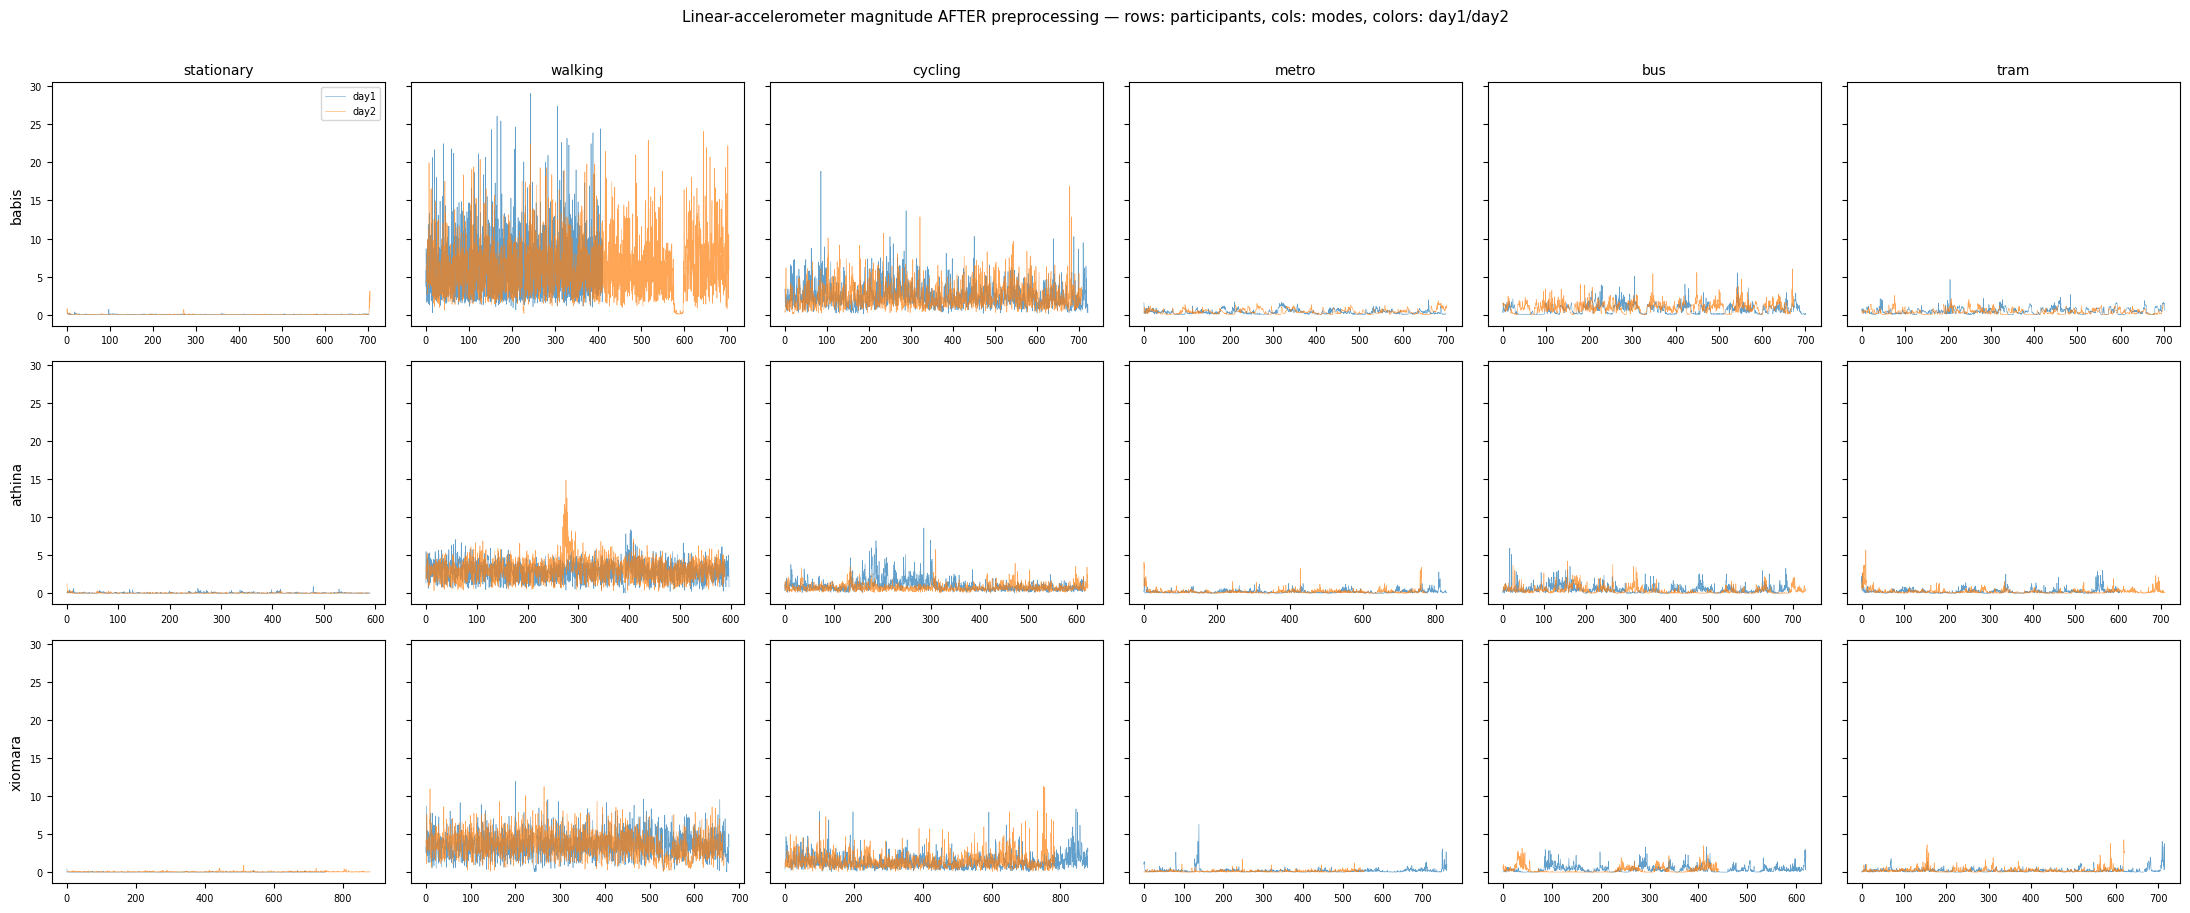

In [17]:
fig, axes = plt.subplots(len(PARTICIPANTS), len(MODES), figsize=(22, 9), sharey=True)
if axes.ndim == 1:
    axes = axes.reshape(1, -1)

for i, p in enumerate(PARTICIPANTS):
    for j, m in enumerate(MODES):
        ax = axes[i, j]
        any_plotted = False
        for d, color in zip(DAYS, ['tab:blue', 'tab:orange']):
            path = INTERIM_DIR / f'{p}_{m}_{d}.csv'
            if not path.exists():
                continue
            df = pd.read_csv(path)
            mag = np.sqrt(df[['lin_ax', 'lin_ay', 'lin_az']].pow(2).sum(axis=1))
            step = max(1, len(df) // 1500)
            ax.plot(df['t'][::step], mag[::step], linewidth=0.4, alpha=0.7, color=color, label=d)
            any_plotted = True
        if not any_plotted:
            ax.text(0.5, 0.5, 'no data', ha='center', va='center',
                    transform=ax.transAxes, color='red')
        if i == 0:
            ax.set_title(m, fontsize=10)
        if j == 0:
            ax.set_ylabel(p, fontsize=10)
        ax.tick_params(labelsize=7)

handles, labels = axes[0, 0].get_legend_handles_labels()
if handles:
    axes[0, 0].legend(fontsize=7, loc='upper right')

plt.suptitle('Linear-accelerometer magnitude AFTER preprocessing — rows: participants, cols: modes, colors: day1/day2',
             y=1.01, fontsize=11)
plt.tight_layout()
plt.show()

## Spot-check: one session, raw vs preprocessed

Pick one session and plot raw vs processed to verify the resampling and trimming worked.

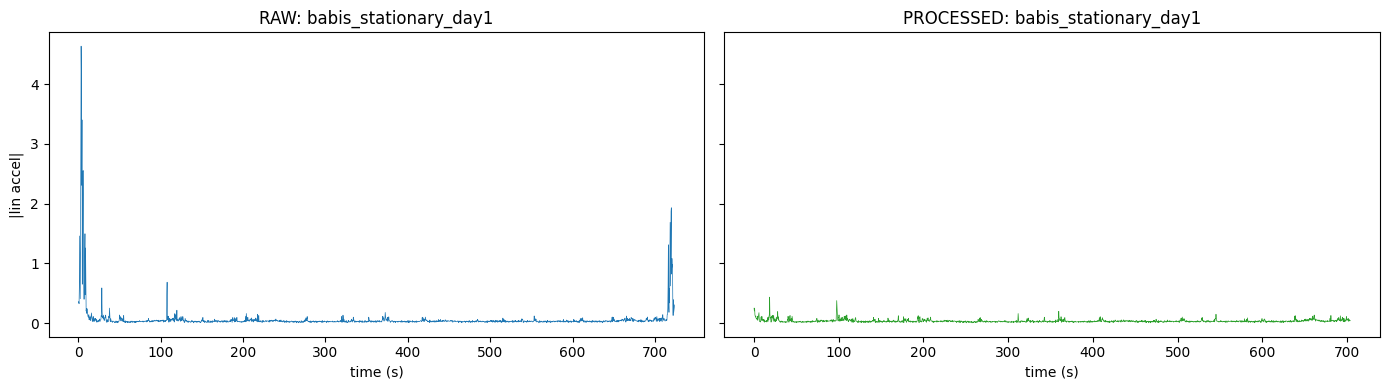

In [18]:
# Pick the first OK session for inspection
if len(ok_df) > 0:
    spot_session = ok_df.iloc[0]['session_id']
    spot_parts = spot_session.split('_')
    p_sp, m_sp, d_sp = spot_parts[0], spot_parts[1], spot_parts[2]
    folder = DATA_ROOT / p_sp / f'{m_sp}_{d_sp}'
    sensor_paths = discover_session_sensors(folder)

    fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=True)

    # raw
    if 'linear_accelerometer' in sensor_paths:
        raw_df = load_phyphox_csv(sensor_paths['linear_accelerometer'])
        t_col = find_time_column(raw_df)
        v_cols = find_value_columns(raw_df, t_col)[:3]
        raw_t = pd.to_numeric(raw_df[t_col], errors='coerce').to_numpy()
        raw_v = raw_df[v_cols].apply(pd.to_numeric, errors='coerce').to_numpy()
        raw_t = raw_t - raw_t[0]
        raw_mag = np.sqrt(np.nansum(raw_v**2, axis=1))
        step = max(1, len(raw_t) // 2000)
        axes[0].plot(raw_t[::step], raw_mag[::step], linewidth=0.5)
        axes[0].set_title(f'RAW: {spot_session}')
        axes[0].set_xlabel('time (s)')
        axes[0].set_ylabel('|lin accel|')

    # processed
    proc_df = pd.read_csv(INTERIM_DIR / f'{spot_session}.csv')
    proc_mag = np.sqrt(proc_df[['lin_ax', 'lin_ay', 'lin_az']].pow(2).sum(axis=1))
    step = max(1, len(proc_df) // 2000)
    axes[1].plot(proc_df['t'][::step], proc_mag[::step], linewidth=0.5, color='tab:green')
    axes[1].set_title(f'PROCESSED: {spot_session}')
    axes[1].set_xlabel('time (s)')

    plt.tight_layout()
    plt.show()
else:
    print('No OK sessions to inspect.')

## Summary

After running this notebook you should have:

- `data/interim/<session_id>.csv` for every OK session.
- `data/interim/sessions_index.csv` listing all OK sessions with metadata.
- `data/reports/preprocessing_log.csv` with diagnostics (duplicates dropped, gaps, etc.).
- `data/reports/post_preprocessing_stats.csv` with per-session magnitude stats.



1. *Filename heterogeneity across phyphox versions resolved via fuzzy alias matching.*
2. *Duplicate timestamps (under 1% per session) removed before resampling, keeping the first occurrence.*
3. *Sampling-rate heterogeneity (one device at ~100 Hz, two at ~50 Hz) resolved by uniform resampling to a common 50 Hz target grid via linear interpolation.*
4. *Edge artefacts (start/stop button presses, phone adjustment) addressed by trimming 10 s from each end of every recording after resampling.*
5. *Sensor missingness (Athina's barometer) handled by NaN-filling the column, with barometer features excluded from the main model — see plan section 8.*

